# 1. Data and differential expression

GSE218039: placental RNA-seq from 30 preterm infants (14 developed ROP, 16 did not).
Counts are normalized to log2(CPM + 1), then a per-gene t-test builds the candidate pool for the genetic algorithm.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, symbols, name, RESULTS
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, RED = "#184E7D", "#B8B8B8", "#A4243B"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

expr, y, meta = load()
sym = symbols()

In [2]:
print(f"{expr.shape[0]} samples, {expr.shape[1]} genes")
meta.assign(rop=meta.rop.map({True: "ROP", False: "no ROP"})).value_counts(["rop"]).to_frame("n")

30 samples, 60664 genes


,n
rop,
no ROP,16
ROP,14


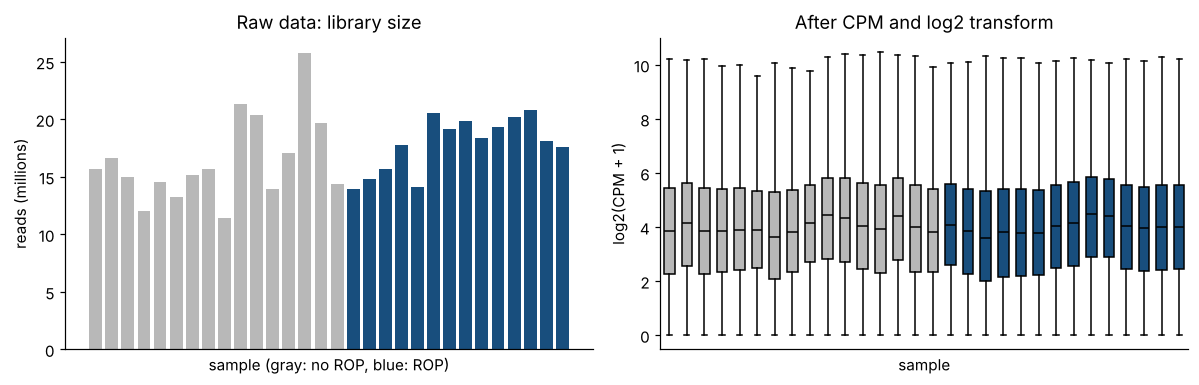

In [3]:
from src.data import load_counts

counts = load_counts()[expr.index]
colors = [BLUE if v else GRAY for v in y]
order = np.argsort(y, kind="stable")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.bar(range(30), counts.sum().to_numpy()[order] / 1e6, color=np.array(colors)[order])
a.set(title="Raw data: library size", ylabel="reads (millions)", xticks=[], xlabel="sample (gray: no ROP, blue: ROP)")

expressed = expr.loc[:, (2 ** expr - 1 >= 1).sum() >= 15]
box = b.boxplot(expressed.iloc[order].T.to_numpy(), patch_artist=True, showfliers=False, widths=0.6,
                medianprops={"color": "black"})
for patch, c in zip(box["boxes"], np.array(colors)[order]):
    patch.set_facecolor(c)
b.set(title="After CPM and log2 transform", ylabel="log2(CPM + 1)", xticks=[], xlabel="sample")
fig.tight_layout()
fig.savefig(FIG / "normalization.png", dpi=200)

In [4]:
from src.deg import ttest, pool, KNOWN

deg = ttest(expr, y)
print(f"{len(deg)} genes tested, {(deg.padj < 0.05).sum()} pass FDR < 0.05")

big = deg[deg.log2fc.abs() > 1].head(10)
big.assign(gene=[name(g, sym) for g in big.index]).set_index("gene").round(6)

42638 genes tested, 3 pass FDR < 0.05


,log2fc,p,padj
gene,,,
HELLPAR,1.623389,0.000002,0.041201
AQP11,-1.004558,0.000003,0.041201
RTN4RL2,1.334156,0.000009,0.094974
HLA-V,1.017996,0.000011,0.094974
TLE6,1.019311,0.000014,0.096394
PLAC8,2.209019,0.000060,0.243449
NOG,2.172486,0.000063,0.243449
HLA-G,2.927366,0.000085,0.251626
ASAP3,1.249315,0.000130,0.307527


In [5]:
genes = pool(expr, y)
cand = deg[(deg.p < 0.05) & (deg.log2fc.abs() > 1)]
print(f"{len(cand)} DEG candidates + known genes from Huang et al. = {len(genes)} genes in the pool")
print(f"higher in ROP: {(cand.log2fc > 0).sum()}, lower in ROP: {(cand.log2fc < 0).sum()}")

121 DEG candidates + known genes from Huang et al. = 124 genes in the pool
higher in ROP: 99, lower in ROP: 22


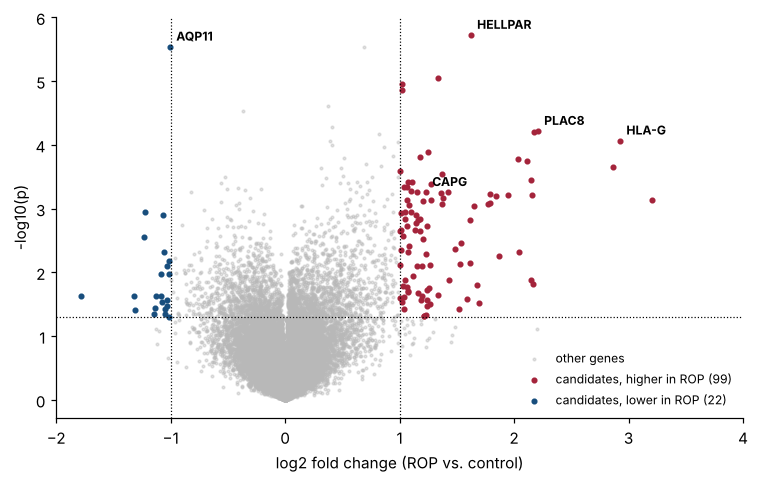

In [6]:
up = cand[cand.log2fc > 0].index
down = cand[cand.log2fc < 0].index
rest = deg.index.difference(cand.index)
logp = -np.log10(deg.p)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(deg.log2fc[rest], logp[rest], s=3, c=GRAY, alpha=0.4, label="other genes", rasterized=True)
ax.scatter(deg.log2fc[up], logp[up], s=9, c=RED, label=f"candidates, higher in ROP ({len(up)})")
ax.scatter(deg.log2fc[down], logp[down], s=9, c=BLUE, label=f"candidates, lower in ROP ({len(down)})")
for g in ["ENSG00000281344", "ENSG00000178301", "ENSG00000145287", "ENSG00000204632", "ENSG00000042493"]:
    ax.annotate(name(g, sym), (deg.log2fc[g], logp[g]), xytext=(4, 4), textcoords="offset points", fontsize=8, weight="bold")
ax.axhline(-np.log10(0.05), ls=":", c="k", lw=0.8)
for x in (-1, 1):
    ax.axvline(x, ls=":", c="k", lw=0.8)
ax.set(xlabel="log2 fold change (ROP vs. control)", ylabel="-log10(p)", xlim=(-2, 4))
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "volcano.png", dpi=200)